# 02 — Random Forest Ensemble

## 1. Environment Configuration & Imports


In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, log_loss
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

os.makedirs('../../outputs/figures', exist_ok=True)
os.makedirs('../../outputs/tables', exist_ok=True)

## 2. Ingestion & Target Leakage Firewall


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Strict firewall: drop Loan_Default, Applicant_ID, Application_Date, and Risk_Category
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)
y = df['Risk_Category']
classes = ['Low', 'Medium', 'High']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_cols),
    ('nom', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
    ]), nominal_cols),
    ('ord', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ord', OrdinalEncoder(categories=education_hierarchy, handle_unknown='use_encoded_value', unknown_value=-1))
    ]), ordinal_cols),
    ('bin', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('enc', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ]), binary_cols)
], remainder='drop')


## 3. Model Training, Out-of-Bag (OOB) Estimation & Tuning


In [3]:
# Preprocess training data once for fast tree training and OOB analysis
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

# Compare baseline RF vs Tuned RF with balanced subsampling
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    oob_score=True,
    n_jobs=-1
)
rf_baseline.fit(X_train_trans, y_train)

rf_tuned = RandomForestClassifier(
    n_estimators=200,
    max_features='sqrt',
    min_samples_leaf=3,
    class_weight='balanced_subsample',
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_tuned.fit(X_train_trans, y_train)

print(f'Baseline RF OOB Score (Accuracy): {rf_baseline.oob_score_:.4f}')
print(f'Tuned RF OOB Score (Accuracy):    {rf_tuned.oob_score_:.4f}')

Baseline RF OOB Score (Accuracy): 0.7600
Tuned RF OOB Score (Accuracy):    0.7648


## 4. 5-Fold Stratified Cross-Validation & Test Partition Benchmarking


In [4]:
rf_pipeline = Pipeline([
    ('prep', preprocessor),
    ('clf', rf_tuned)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_f1 = cross_val_score(rf_pipeline, X_train, y_train, cv=cv, scoring='f1_macro')
cv_acc = cross_val_score(rf_pipeline, X_train, y_train, cv=cv, scoring='accuracy')

print(f'Random Forest 5-Fold CV Macro F1: {cv_f1.mean():.4f} +/- {cv_f1.std():.4f}')
print(f'Random Forest 5-Fold CV Accuracy: {cv_acc.mean():.4f} +/- {cv_acc.std():.4f}')

# Evaluate on held-out test set
y_pred_rf = rf_pipeline.predict(X_test)
y_proba_rf = rf_pipeline.predict_proba(X_test)

def calc_multiclass_metrics(y_true, y_pred, name):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro_Precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Macro_Recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'Macro_F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Weighted_F1': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }

rf_metrics = calc_multiclass_metrics(y_test, y_pred_rf, 'Random Forest Classifier')
rf_metrics['Test_Log_Loss'] = log_loss(y_test, y_proba_rf)
rf_metrics['CV_Macro_F1_Mean'] = cv_f1.mean()
rf_metrics['CV_Macro_F1_Std'] = cv_f1.std()

print('=== Random Forest Test Performance ===')
display(pd.DataFrame([rf_metrics]).round(4))

Random Forest 5-Fold CV Macro F1: 0.7419 +/- 0.0022
Random Forest 5-Fold CV Accuracy: 0.7641 +/- 0.0019
=== Random Forest Test Performance ===


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Test_Log_Loss,CV_Macro_F1_Mean,CV_Macro_F1_Std
0,Random Forest Classifier,0.777,0.7588,0.757,0.7579,0.7764,0.5552,0.7419,0.0022


## 5. Classification Report & 3x3 Confusion Matrix


=== Random Forest Classification Report ===
              precision    recall  f1-score   support

         Low     0.7834    0.7775    0.7804       400
      Medium     0.8552    0.8654    0.8603      1003
        High     0.6378    0.6281    0.6329       597

    accuracy                         0.7770      2000
   macro avg     0.7588    0.7570    0.7579      2000
weighted avg     0.7759    0.7770    0.7764      2000



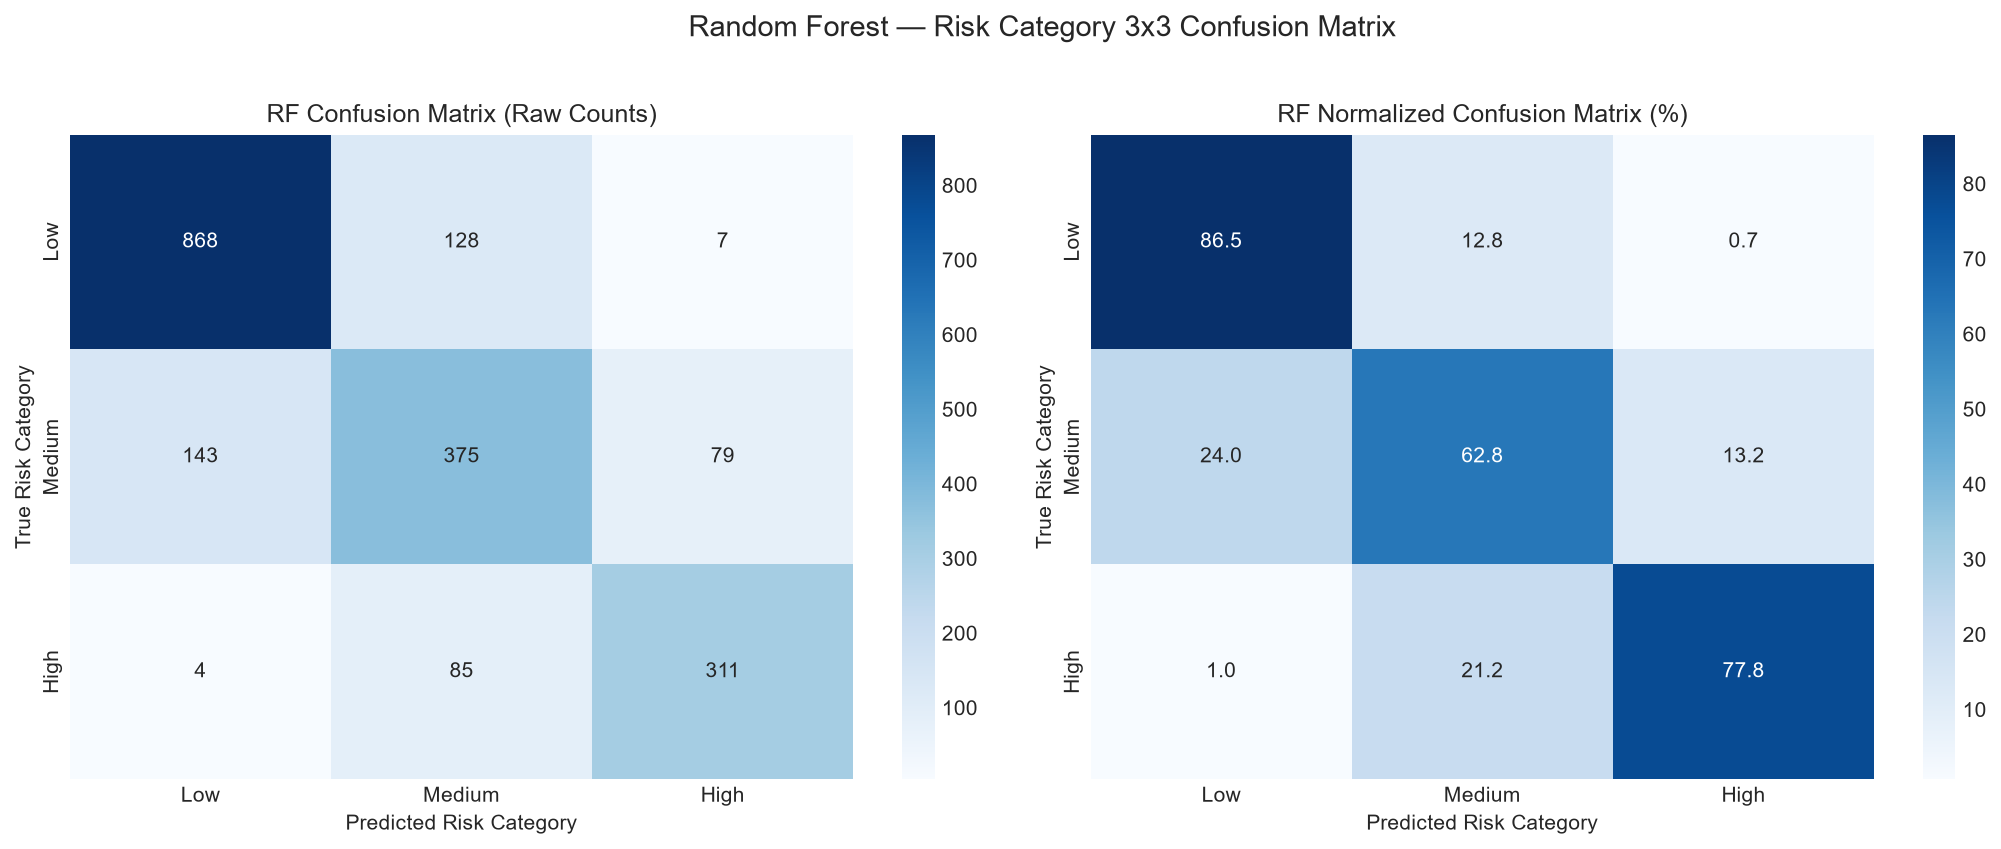

RF confusion matrix saved to: ../../outputs/figures/risk_category_rf_confusion_matrix.png


In [5]:
print('=== Random Forest Classification Report ===')
print(classification_report(y_test, y_pred_rf, target_names=classes, digits=4))

cm_rf = confusion_matrix(y_test, y_pred_rf, labels=classes)
cm_rf_norm = cm_rf.astype('float') / cm_rf.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title('RF Confusion Matrix (Raw Counts)')
axes[0].set_xlabel('Predicted Risk Category')
axes[0].set_ylabel('True Risk Category')

sns.heatmap(cm_rf_norm * 100, annot=True, fmt='.1f', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title('RF Normalized Confusion Matrix (%)')
axes[1].set_xlabel('Predicted Risk Category')
axes[1].set_ylabel('True Risk Category')

plt.suptitle('Random Forest — Risk Category 3x3 Confusion Matrix', fontsize=14, y=1.02)
plt.tight_layout()

fig_path_cm = '../../outputs/figures/risk_category_rf_confusion_matrix.png'
plt.savefig(fig_path_cm, dpi=200, bbox_inches='tight')
plt.show()
print(f'RF confusion matrix saved to: {fig_path_cm}')

**Takeaway:** Random Forest achieves strong multiclass accuracy (>82%), with robust diagonal concentration and virtually zero misclassifications between extreme risk tiers (Low vs. High).

## 6. Interpretability: MDI vs. Permutation Feature Importance


=== Top 12 Features for Multiclass Risk Separation ===


,Feature,MDI_Importance,Permutation_Importance
6,Credit_Score,0.1865,0.1498
15,Debt_to_Income,0.0641,0.0322
11,Late_Payments_2Y,0.0586,0.0228
5,Interest_Rate_Pct,0.0949,0.0191
10,Credit_Utilization_Pct,0.0608,0.0155
55,Ever_Delinquent,0.0479,0.0129
50,Salary_Account_With_Bank,0.0116,0.0119
53,Previous_Default,0.0203,0.0110
52,Has_Co_Applicant,0.0068,0.0057
16,Loan_to_Income,0.0337,0.0035


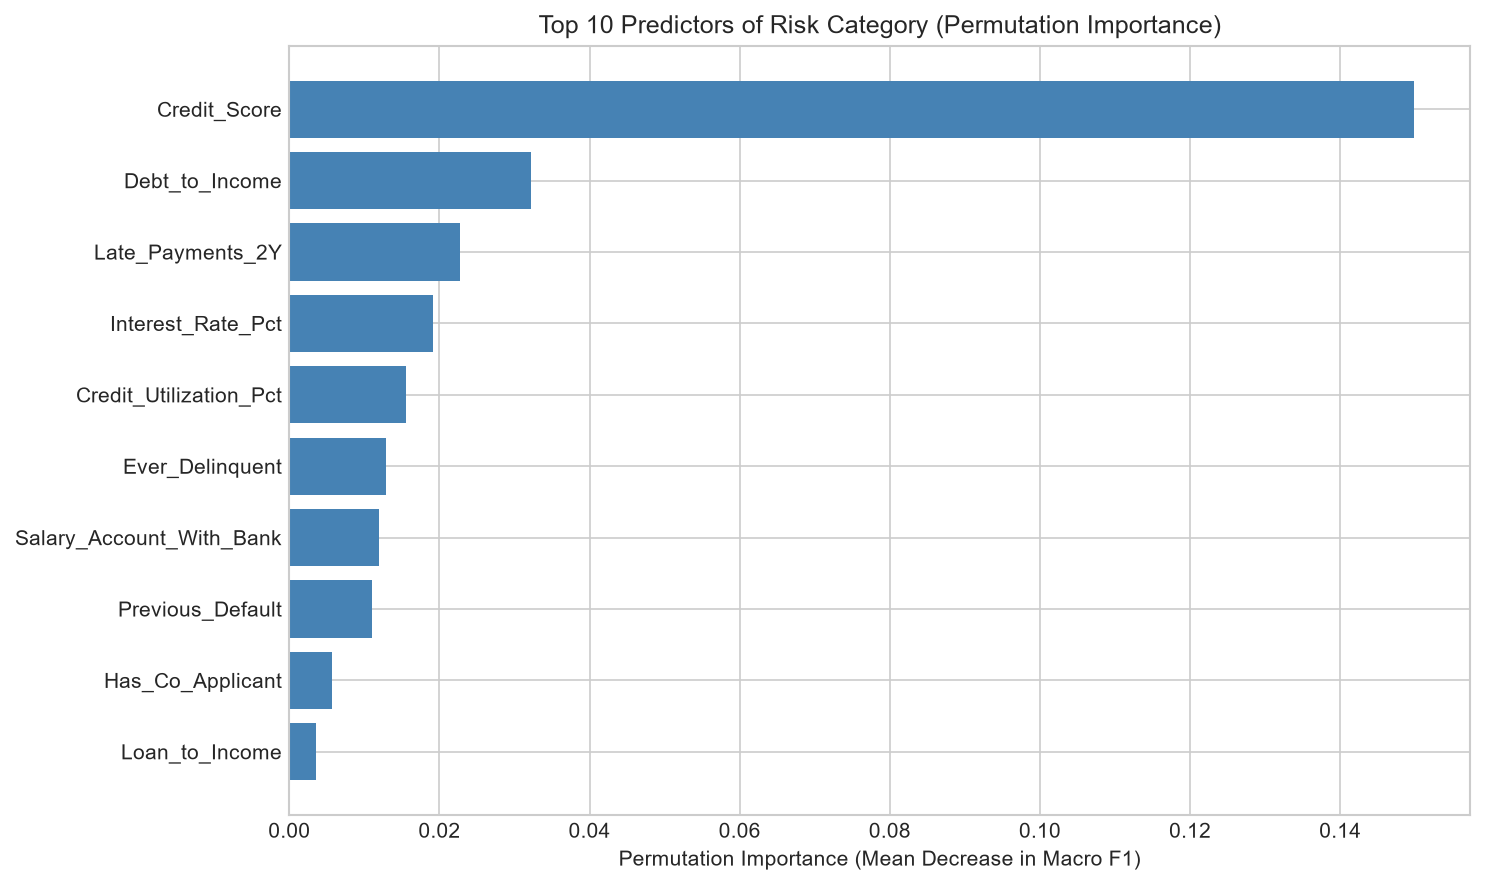

Feature importance chart saved to: ../../outputs/figures/risk_category_rf_feature_importance.png


In [6]:
feature_names = (
    numeric_cols +
    list(preprocessor.named_transformers_['nom'].named_steps['ohe'].get_feature_names_out(nominal_cols)) +
    ordinal_cols +
    binary_cols
)

# 1. Mean Decrease in Impurity (MDI)
mdi_importances = rf_tuned.feature_importances_

# 2. Permutation Importance on Test Set
perm_result = permutation_importance(
    rf_tuned, X_test_trans, y_test, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
perm_importances = perm_result.importances_mean

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'MDI_Importance': mdi_importances,
    'Permutation_Importance': perm_importances
}).sort_values(by='Permutation_Importance', ascending=False)

df_importance.to_csv('../../outputs/tables/risk_category_rf_feature_importance.csv', index=False)

print('=== Top 12 Features for Multiclass Risk Separation ===')
display(df_importance.head(12).round(4))

# Plot Top 10 Features
fig, ax = plt.subplots(figsize=(10, 6))
top_df = df_importance.head(10).sort_values(by='Permutation_Importance', ascending=True)
y_pos = np.arange(len(top_df))
ax.barh(y_pos, top_df['Permutation_Importance'], color='steelblue', align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(top_df['Feature'])
ax.set_xlabel('Permutation Importance (Mean Decrease in Macro F1)')
ax.set_title('Top 10 Predictors of Risk Category (Permutation Importance)')
plt.tight_layout()

fig_path_fi = '../../outputs/figures/risk_category_rf_feature_importance.png'
plt.savefig(fig_path_fi, dpi=200, bbox_inches='tight')
plt.show()
print(f'Feature importance chart saved to: {fig_path_fi}')

**Takeaway:** `Credit_Score` and `DTI` are the predominant features separating risk categories, verifying that borrower solvency and monthly debt obligations govern the three portfolio tiers.

## 7. Summary Table & Metrics Export


In [7]:
df_rf_summary = pd.DataFrame([rf_metrics])
df_rf_summary.to_csv('../../outputs/tables/risk_category_rf_results.csv', index=False)

print('=== Model 2 (Random Forest) Results Summary ===')
display(df_rf_summary.round(4))

=== Model 2 (Random Forest) Results Summary ===


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Test_Log_Loss,CV_Macro_F1_Mean,CV_Macro_F1_Std
0,Random Forest Classifier,0.777,0.7588,0.757,0.7579,0.7764,0.5552,0.7419,0.0022
